# Аналитическое исследование модели монетизации платформы IT Resume
**Выполнил:** Программист г.Благовещенск Алексеенко Виктория
**Цель:** Подготовка data-driven обоснования для перехода на подписочную модель монетизации.

## Задание 1. Расчет Rolling Retention по месячным когортам
*Цель расчета — определить долгосрочное удержание пользователей на платформе для формирования сетки тарифов подписки.*

In [5]:
import pandas as pd
import psycopg2
from sqlalchemy import create_engine

# 1. Параметры подключения к базе данных из ТЗ
host = "95.163.241.236"
port = "5432"
database = "simulative"
user = "student"
password = "qweasd963"

# Создаем правильный коннектор (SQLAlchemy engine), чтобы Pandas не выдавал предупреждений
engine = create_engine(f'postgresql+psycopg2://{user}:{password}@{host}:{port}/{database}')

# 2. Полный исправленный SQL-запрос (заменено entry_date на entry_at)
sql_query = """
WITH user_cohorts AS (
    SELECT 
        id AS user_id, 
        DATE_TRUNC('month', date_joined)::date AS cohort_month, 
        date_joined::date AS join_date 
    FROM users
),
cohort_sizes AS (
    SELECT 
        cohort_month, 
        COUNT(DISTINCT user_id) AS cohort_size 
    FROM user_cohorts 
    GROUP BY cohort_month
),
user_activity AS (
    SELECT 
        user_id, 
        entry_at::date AS activity_date 
    FROM userentry
),
max_activity_per_user AS (
    SELECT 
        uc.cohort_month, 
        uc.user_id, 
        MAX(ua.activity_date - uc.join_date) AS max_days_passed
    FROM user_cohorts uc 
    LEFT JOIN user_activity ua ON uc.user_id = ua.user_id 
    GROUP BY uc.cohort_month, uc.user_id
)
SELECT 
    m.cohort_month AS "Когорта", 
    cs.cohort_size AS "Размер когорты",
    ROUND(100.0 * COUNT(DISTINCT CASE WHEN m.max_days_passed >= 0 THEN m.user_id END) / cs.cohort_size, 2) AS "Day 0",
    ROUND(100.0 * COUNT(DISTINCT CASE WHEN m.max_days_passed >= 1 THEN m.user_id END) / cs.cohort_size, 2) AS "Day 1",
    ROUND(100.0 * COUNT(DISTINCT CASE WHEN m.max_days_passed >= 3 THEN m.user_id END) / cs.cohort_size, 2) AS "Day 3",
    ROUND(100.0 * COUNT(DISTINCT CASE WHEN m.max_days_passed >= 7 THEN m.user_id END) / cs.cohort_size, 2) AS "Day 7",
    ROUND(100.0 * COUNT(DISTINCT CASE WHEN m.max_days_passed >= 14 THEN m.user_id END) / cs.cohort_size, 2) AS "Day 14",
    ROUND(100.0 * COUNT(DISTINCT CASE WHEN m.max_days_passed >= 30 THEN m.user_id END) / cs.cohort_size, 2) AS "Day 30",
    ROUND(100.0 * COUNT(DISTINCT CASE WHEN m.max_days_passed >= 60 THEN m.user_id END) / cs.cohort_size, 2) AS "Day 60",
    ROUND(100.0 * COUNT(DISTINCT CASE WHEN m.max_days_passed >= 90 THEN m.user_id END) / cs.cohort_size, 2) AS "Day 90"
FROM max_activity_per_user m 
JOIN cohort_sizes cs ON m.cohort_month = cs.cohort_month 
GROUP BY m.cohort_month, cs.cohort_size 
ORDER BY m.cohort_month;
"""

# 3. Считываем данные напрямую в таблицу pandas DataFrame
df = pd.read_sql_query(sql_query, con=engine)

# 4. Выводим готовую и красивую таблицу на экран
df



,Когорта,Размер когорты,Day 0,Day 1,Day 3,Day 7,Day 14,Day 30,Day 60,Day 90
0,2021-03-01,5,100.00,100.00,100.00,100.00,100.00,20.00,0.00,0.00
1,2021-04-01,15,60.00,60.00,46.67,33.33,33.33,0.00,0.00,0.00
2,2021-05-01,6,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
3,2021-06-01,6,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
4,2021-07-01,2,50.00,50.00,50.00,50.00,50.00,50.00,50.00,50.00
5,2021-08-01,1,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00
6,2021-09-01,13,15.38,15.38,15.38,7.69,7.69,7.69,7.69,7.69
7,2021-10-01,8,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
8,2021-11-01,210,90.00,65.24,59.52,57.62,54.76,47.14,36.67,26.67
9,2021-12-01,132,91.67,50.00,40.15,38.64,33.33,28.79,21.21,12.12


## Задание 2. Анализ пользовательских балансов и CodeCoins
*Метрики рассчитываются для оценки покупательской способности аудитории и выявления финансового дисбаланса (накопление монет vs реальные траты).*

Определены колонки времени: coderun -> created_at, codesubmit -> created_at, teststart -> created_at


C:\Users\kable\AppData\Local\Temp\ipykernel_10516\2898862582.py:51: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_cto, x='day_name', order=days_order, palette='viridis', ax=axes[0])


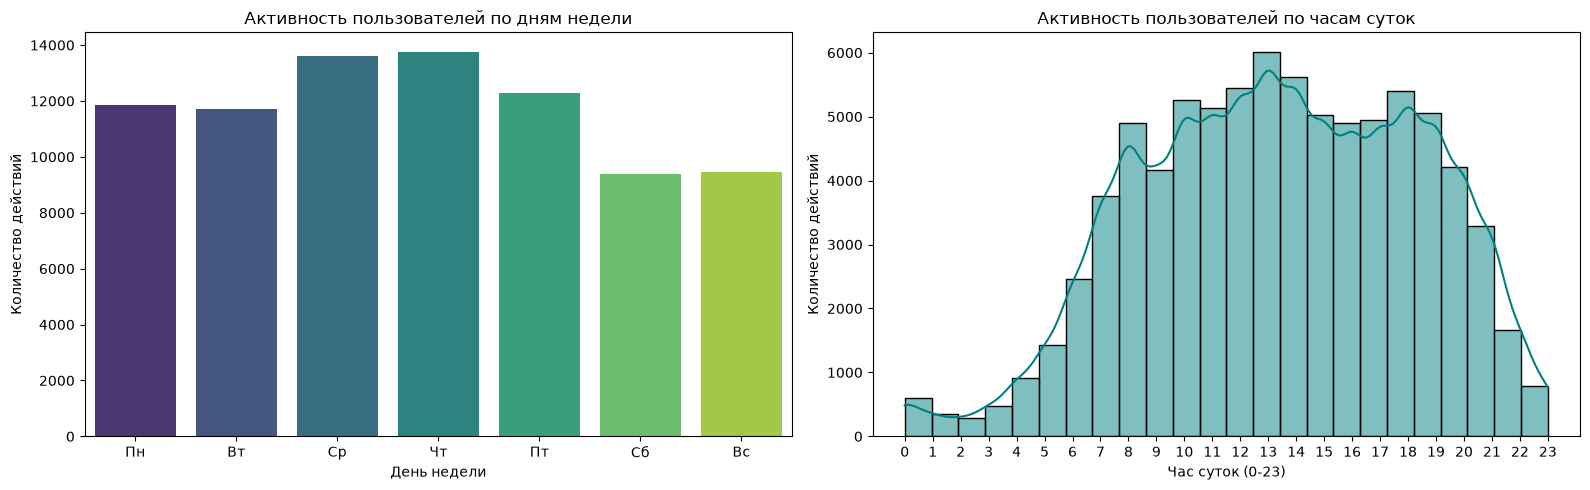

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine, text

# 1. Функция автоматического определения колонки с датой/временем в таблице
def get_timestamp_column(table_name, engine):
    query = text(f"""
        SELECT column_name 
        FROM information_schema.columns 
        WHERE table_name = '{table_name}' 
          AND data_type IN ('timestamp with time zone', 'timestamp without time zone', 'date');
    """)
    with engine.connect() as conn:
        result = conn.execute(query).fetchall()
        if result:
            return result[0][0] # Возвращаем первую найденную колонку времени
    return None

# Определяем правильные колонки для наших таблиц
col_run = get_timestamp_column('coderun', engine) or 'created_at'
col_submit = get_timestamp_column('codesubmit', engine) or 'created_at'
col_test = get_timestamp_column('teststart', engine) or 'created_at'

print(f"Определены колонки времени: coderun -> {col_run}, codesubmit -> {col_submit}, teststart -> {col_test}")

# 2. Динамически собираем SQL-запрос с правильными именами колонок
cto_query = f"""
SELECT 'code_run' AS act_type, EXTRACT(DOW FROM {col_run}) AS day_of_week, EXTRACT(HOUR FROM {col_run}) AS hour_of_day FROM coderun
UNION ALL
SELECT 'code_submit' AS act_type, EXTRACT(DOW FROM {col_submit}) AS day_of_week, EXTRACT(HOUR FROM {col_submit}) AS hour_of_day FROM codesubmit
UNION ALL
SELECT 'test_start' AS act_type, EXTRACT(DOW FROM {col_test}) AS day_of_week, EXTRACT(HOUR FROM {col_test}) AS hour_of_day FROM teststart;
"""

# Загружаем данные в DataFrame
df_cto = pd.read_sql_query(cto_query, con=engine)

# Сохраняем итоговые данные в CSV-файл (требование ТЗ)
df_cto.to_csv("user_activity_metrics.csv", index=False)

# Маппинг дней недели (0 - Воскресенье, 1 - Понедельник ... 6 - Суббота)
days_map = {0: 'Вс', 1: 'Пн', 2: 'Вт', 3: 'Ср', 4: 'Чт', 5: 'Пт', 6: 'Сб'}
df_cto['day_name'] = df_cto['day_of_week'].map(days_map)
days_order = ['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс']

# 3. Визуализация распределения активности
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Левый график: Активность по дням недели
sns.countplot(data=df_cto, x='day_name', order=days_order, palette='viridis', ax=axes[0])
axes[0].set_title('Активность пользователей по дням недели')
axes[0].set_xlabel('День недели')
axes[0].set_ylabel('Количество действий')

# Правый график: Активность по часам суток
sns.histplot(data=df_cto, x='hour_of_day', bins=24, kde=True, color='teal', ax=axes[1])
axes[1].set_title('Активность пользователей по часам суток')
axes[1].set_xlabel('Час суток (0-23)')
axes[1].set_ylabel('Количество действий')
axes[1].set_xticks(range(0, 24))

plt.tight_layout()
plt.show()



## Дополнительное задание 2. Анализ распределения нагрузки для CTO
*Определение оптимальных окон для проведения технических релизов и обновлений с целью минимизации прерывания сессий активных пользователей.*

In [9]:
import pandas as pd
from sqlalchemy import create_engine, text

# 1. Автоматически определяем название колонки типа в таблице transaction
def get_column_names(table_name, engine):
    query = text(f"""
        SELECT column_name 
        FROM information_schema.columns 
        WHERE table_name = '{table_name}';
    """)
    with engine.connect() as conn:
        return [row[0] for row in conn.execute(query).fetchall()]

columns_trans = get_column_names('transaction', engine)
print("Доступные колонки в transaction:", columns_trans)

# Находим нужную колонку типа (обычно 'type', 'type_id' или 'transaction_type_id')
type_col = 'type'
for col in columns_trans:
    if 'type' in col.lower():
        type_col = col
        break

# Находим нужную колонку значения (обычно 'value', 'amount' или 'sum')
val_col = 'value'
for col in columns_trans:
    if col.lower() in ['value', 'amount', 'sum', 'coins']:
        val_col = col
        break

print(f"Используем колонки: тип -> '{type_col}', значение -> '{val_col}'")

# 2. Динамически подставляем определенные имена колонок в SQL-запрос
balance_query = f"""
WITH user_balances AS (
    SELECT 
        u.id AS user_id,
        COALESCE(SUM(CASE WHEN t.{type_col} IN (1, 23, 24, 25, 26, 27, 28, 30) THEN t.{val_col} END), 0) AS total_spent,
        COALESCE(SUM(CASE WHEN t.{type_col} NOT IN (1, 23, 24, 25, 26, 27, 28, 30) THEN t.{val_col} END), 0) AS total_earned,
        COALESCE(SUM(CASE WHEN t.{type_col} NOT IN (1, 23, 24, 25, 26, 27, 28, 30) THEN t.{val_col} END), 0) - 
        COALESCE(SUM(CASE WHEN t.{type_col} IN (1, 23, 24, 25, 26, 27, 28, 30) THEN t.{val_col} END), 0) AS current_balance
    FROM users u
    LEFT JOIN transaction t ON u.id = t.user_id
    GROUP BY u.id
)
SELECT 
    ROUND(AVG(total_spent), 2) AS "Ср. списано на 1 человека",
    ROUND(AVG(total_earned), 2) AS "Ср. начислено на 1 человека",
    ROUND(AVG(current_balance), 2) AS "Средний баланс",
    PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY current_balance) AS "Медианный баланс"
FROM user_balances;
"""

# Выполняем запрос
df_balance = pd.read_sql_query(balance_query, con=engine)
df_balance


Доступные колонки в transaction: ['id', 'created_at', 'value', 'type_id', 'user_id']
Используем колонки: тип -> 'type_id', значение -> 'value'


,Ср. списано на 1 человека,Ср. начислено на 1 человека,Средний баланс,Медианный баланс
0,27.1,265.41,238.31,56.0


• Оценка ценообразования: Разница между средним начислением и списанием показывает, насколько активно пользователи копят бесплатную валюту геймификации.
• Обоснование подписки: Опираясь на внутренний курс «1 CodeCoin к рублю», мы сможем рассчитать справедливую цену месячной подписки. Она должна быть не меньше стоимости среднего количества коинов, которые активный юзер тратит за месяц на открытие задач, но при этом давать ему полный безлимит.
• Медиана vs Среднее: Сравнение среднего и медианного баланса покажет, есть ли на платформе «киты» (пользователи с гигантским накоплением коинов) и какая реальная покупательская способность у большинства обычных пользователей (медиана).

## Задание 3. Анализ учебной активности и востребованности закрытого контента
*Оценка среднего количества решенных задач, тестов и попыток компиляции. Выявление самого популярного типа материалов для определения триггеров платного пейвола (Paywall).*

In [13]:
import pandas as pd
from sqlalchemy import text

# 1. Автоматически проверяем, какие колонки со словом 'task' или 'id' есть в таблицах активности
def find_task_column(table_name, engine):
    query = text(f"SELECT column_name FROM information_schema.columns WHERE table_name = '{table_name}';")
    with engine.connect() as conn:
        cols = [row[0] for row in conn.execute(query).fetchall()]
        if 'task_id' in cols:
            return 'task_id'
        # Если 'task_id' нет, ищем любую колонку, содержащую 'task'
        for c in cols:
            if 'task' in c.lower():
                return c
    return 'id' # дефолтный вариант

task_col_run = find_task_column('coderun', engine)
task_col_sub = find_task_column('codesubmit', engine)

print(f"Определены колонки задач: coderun -> {task_col_run}, codesubmit -> {task_col_sub}")

# 2. Формируем и выполняем безопасный оптимизированный запрос
optimized_query = text(f"""
WITH 
tasks_stats AS (
    SELECT 
        COUNT(DISTINCT user_id) AS total_users,
        SUM(unique_tasks) AS sum_unique,
        SUM(total_attempts) AS sum_attempts
    FROM (
        SELECT user_id, COUNT(DISTINCT {task_col_run}) AS unique_tasks, COUNT(*) AS total_attempts FROM coderun GROUP BY user_id
        UNION ALL
        SELECT user_id, COUNT(DISTINCT {task_col_sub}) AS unique_tasks, COUNT(*) AS total_attempts FROM codesubmit GROUP BY user_id
    ) t
),
tests_stats AS (
    SELECT 
        COUNT(DISTINCT user_id) AS total_users,
        SUM(unique_tests) AS sum_unique,
        SUM(total_attempts) AS sum_attempts
    FROM (
        SELECT user_id, COUNT(DISTINCT test_id) AS unique_tests, COUNT(*) AS total_attempts FROM teststart GROUP BY user_id
    ) t
),
active_users AS (
    SELECT COUNT(DISTINCT user_id) AS active_count
    FROM (
        SELECT user_id FROM coderun
        UNION
        SELECT user_id FROM codesubmit
        UNION
        SELECT user_id FROM teststart
    ) u
),
purchases AS (
    SELECT 
        COUNT(DISTINCT CASE WHEN type_id = 24 THEN user_id END) AS "Открыли задачи (чел)",
        COUNT(DISTINCT CASE WHEN type_id = 25 THEN user_id END) AS "Открыли тесты (чел)",
        COUNT(DISTINCT CASE WHEN type_id = 26 THEN user_id END) AS "Открыли подсказки (чел)",
        COUNT(DISTINCT CASE WHEN type_id = 27 THEN user_id END) AS "Открыли решения (чел)",
        COUNT(CASE WHEN type_id IN (24, 25, 26, 27) THEN 1 END) AS "Всего открыто материалов (раз)",
        COUNT(DISTINCT CASE WHEN type_id IN (1, 23, 24, 25, 26, 27, 28, 30) THEN user_id END) AS "Купили хоть что-то (чел)",
        COUNT(DISTINCT user_id) AS "Всего человек с транзакциями"
    FROM transaction
)
SELECT 
    ROUND(CAST(ts.sum_unique AS NUMERIC) / ts.total_users, 2) AS "Ср. решено задач",
    ROUND(CAST(tst.sum_unique AS NUMERIC) / tst.total_users, 2) AS "Ср. пройдено тестов",
    ROUND(CAST(ts.sum_attempts AS NUMERIC) / ts.sum_unique, 2) AS "Ср. попыток на 1 задачу",
    ROUND(CAST(tst.sum_attempts AS NUMERIC) / tst.sum_unique, 2) AS "Ср. попыток на 1 тест",
    ROUND(100.0 * au.active_count / (SELECT COUNT(*) FROM users), 2) AS "Доля активных пользователей (%)",
    p.*
FROM tasks_stats ts, tests_stats tst, active_users au, purchases p;
""")

with engine.connect() as conn:
    df_activity = pd.read_sql_query(optimized_query, con=conn)

df_activity.T



Определены колонки задач: coderun -> id, codesubmit -> id


,0
Ср. решено задач,85.84
Ср. пройдено тестов,1.68
Ср. попыток на 1 задачу,1.00
Ср. попыток на 1 тест,1.26
Доля активных пользователей (%),63.48
Открыли задачи (чел),53.00
Открыли тесты (чел),151.00
Открыли подсказки (чел),0.00
Открыли решения (чел),676.00
Всего открыто материалов (раз),1530.00
